Accuracy:  0.7000
Precision: 0.6000
Recall:    0.4766
F1 Score:  0.5312
Confusion Matrix:
 [[159  34]
 [ 56  51]]

Hidden Layer Width Comparison:
     Width  Val Acc  Test Acc  Test F1
   16 -> 8   0.7208    0.7067   0.5319
  64 -> 32   0.7125    0.7100   0.5397
256 -> 128   0.7292    0.7033   0.5436


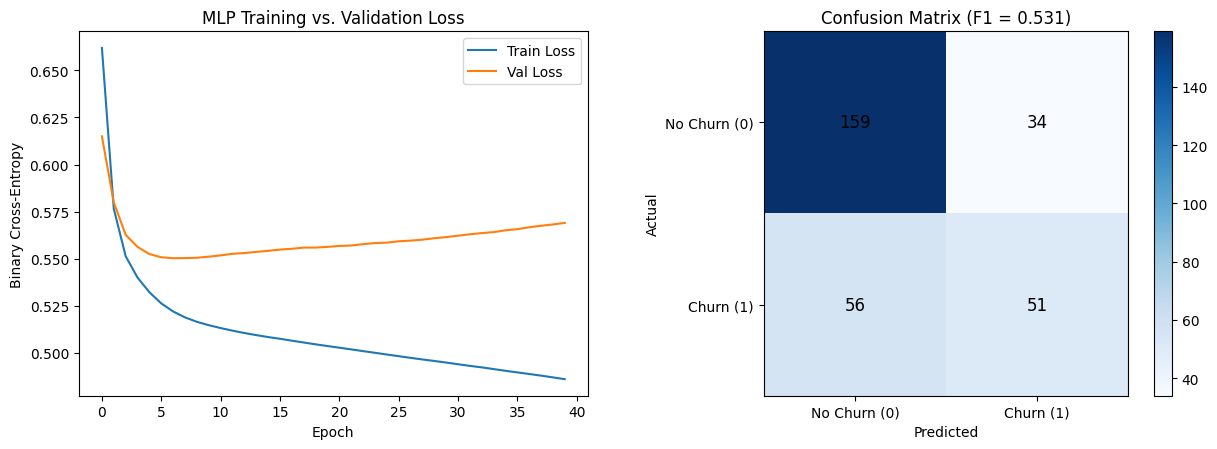

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

# 1. Synthetic customer churn dataset (1,500 customers)
n_cust = 1500
tenure = np.random.randint(1, 73, n_cust)
monthly_charges = np.round(np.random.uniform(25, 120, n_cust), 2)
contract_type = np.random.choice(["Month-to-month", "One-year", "Two-year"], size=n_cust, p=[0.55, 0.25, 0.20])
complaints = np.random.poisson(lam=1.2, size=n_cust)
data_usage = np.round(np.random.gamma(shape=3.0, scale=25.0, size=n_cust), 1)

contract_risk = np.where(contract_type == "Month-to-month", 1.2, np.where(contract_type == "One-year", 0.2, -0.5))
logit = -1.6 - 0.03 * tenure + 0.015 * monthly_charges + contract_risk + 0.45 * complaints - 0.004 * data_usage
prob_churn = 1.0 / (1.0 + np.exp(-logit))
churn = (np.random.rand(n_cust) < prob_churn).astype(int)

df_churn = pd.DataFrame({
    "tenure": tenure,
    "monthly_charges": monthly_charges,
    "contract_type": contract_type,
    "complaints": complaints,
    "data_usage": data_usage,
    "Churn": churn
})

X_raw = df_churn.drop(columns=["Churn"])
y_raw = df_churn["Churn"].values

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

num_cols = ["tenure", "monthly_charges", "complaints", "data_usage"]
cat_cols = ["contract_type"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
])

X_tr_proc = preprocessor.fit_transform(X_train)
X_te_proc = preprocessor.transform(X_test)

def build_mlp(input_dim, width=64):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(width, activation="relu"),
        layers.Dense(width // 2, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

mlp = build_mlp(X_tr_proc.shape[1], width=64)
history = mlp.fit(
    X_tr_proc, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=32,
    verbose=0
)

y_prob = mlp.predict(X_te_proc, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")
print("Confusion Matrix:\n", cm)

# Vary hidden-layer width
widths = [16, 64, 256]
width_results = []
for w in widths:
    tf.random.set_seed(42)
    m_w = build_mlp(X_tr_proc.shape[1], width=w)
    h_w = m_w.fit(X_tr_proc, y_train, validation_split=0.2, epochs=40, batch_size=32, verbose=0)
    pred_w = (m_w.predict(X_te_proc, verbose=0).ravel() >= 0.5).astype(int)
    width_results.append({
        "Width": f"{w} -> {w//2}",
        "Val Acc": round(max(h_w.history["val_accuracy"]), 4),
        "Test Acc": round(accuracy_score(y_test, pred_w), 4),
        "Test F1": round(f1_score(y_test, pred_w), 4)
    })

print("\nHidden Layer Width Comparison:")
print(pd.DataFrame(width_results).to_string(index=False))

# Plots: Training/Validation curves + Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].set_title("MLP Training vs. Validation Loss")
axes[0].legend()

im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["No Churn (0)", "Churn (1)"])
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["No Churn (0)", "Churn (1)"])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"Confusion Matrix (F1 = {f1:.3f})")
for r in range(2):
    for c in range(2):
        axes[1].text(c, r, str(cm[r, c]), ha="center", va="center", color="black", fontsize=12)
plt.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.savefig("exp09_churn_mlp.png", dpi=150, bbox_inches="tight")
plt.show()